# Удалённые вакансии · прогноз опубликованных ставок

В этом ноутбуке можно проверить отбор, разбор оплаты, признаки, сравнение с базой и прогноз для новой карточки. Нажмите **Run All**. По умолчанию используется сохранённый эксперимент, последняя ячейка позволяет повторить обучение.

**Когорта:** «Удалённо» как отдельный формат или один из вариантов в карточке. Ставки в рублях за месяц, смену, час, неделю и действие остаются в своих единицах. Период, налоговая база и форма предложения задаются при прогнозе.

In [1]:
import json, os, subprocess, sys, hashlib
from datetime import datetime
from pathlib import Path

REL = Path("ML/experiments/2026-11-26_remote_model")
roots = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("REMOTE_MODEL_REPO"):
    roots.insert(0, Path(os.environ["REMOTE_MODEL_REPO"]).resolve())
ROOT = next((root for root in roots if (root / REL / "remote_train.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук внутри репозитория или задайте REMOTE_MODEL_REPO.")
EXP = ROOT / REL
RESULTS = EXP / "results"
LOCAL_DEPS = ROOT / "ML/.cache/vahta-model-deps"
for path in (LOCAL_DEPS, ROOT, EXP):
    if path.is_dir() and str(path) not in sys.path:
        sys.path.insert(0, str(path))
import pandas as pd
from IPython import get_ipython
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from remote_data import rate_target, CARD, META
from remote_predict import infer
meta = json.loads((RESULTS / "dataset.json").read_text(encoding="utf-8"))
labels = pd.read_csv(RESULTS / "labels.csv", dtype={"id": str})
unit_ru = {"month":"месяц","shift":"смена","hour":"час","week":"неделя","piece":"действие",
           "lesson":"урок","unspecified":"неизвестен","conflict":"конфликт","no_amount":"нет числа"}
variants = {"empirical":"База по профессии и типу ставки","card":"CatBoost: карточка",
            "rules":"CatBoost: карточка и правила","card_char":"Карточка + символьный TF-IDF",
            "rules_tfidf":"Правила + символьный и словный TF-IDF","ridge":"Ridge и TF-IDF",
            "specialists":"CatBoost по единицам","blend":"Ансамбль CatBoost/Ridge",
            "rules_calibrated":"CatBoost с правилами и калибровкой",
            "augmented_month":"CatBoost с дополнительными месячными кандидатами"}
variants["unit_ridge"] = "Отдельный Ridge + TF-IDF"

## 1. Снимок и качество разметки

Два режима работы видны отдельно. Полный прогон сравнивает, насколько модель воспроизводит опубликованные числа. Для строгой оценки используем только явную единицу карточки или однозначное совпадение суммы и периода в описании. Исключаем военные карточки, признаки партнёрской программы или платного входа, конфликт налога и суммы вне заранее заданных границ.

Если описание говорит о месяце, но число из карточки не связано с периодом, это дополнительный слабый пример. Такие карточки не становятся строгим тестом. Рабочая таблица операторов из GitHub использовалась как источник правил; из 780 её ID только 3 совпадают с этим снимком, поэтому её строки не добавлялись в обучение.

In [2]:
assert len(labels) == meta["remote_cards"] and labels.id.is_unique
assert labels.groupby("group").fold.nunique().max() == 1
counts = labels.groupby("unit").agg(Карточек=("id","size"), Строгих=("strict","sum"))
counts.index = counts.index.map(unit_ru)
display(counts.sort_values("Карточек",ascending=False))
display(labels.groupby("fold").agg(Карточек=("id","size"), Групп=("group","nunique"),
                                    Строгих=("strict","sum")))
display(labels.loc[labels.strict].groupby(["unit","mode"]).size().unstack(fill_value=0))
print(f"Групп источников: {meta['groups']}; числовых целей: {meta['numeric']}; "
      f"строгих: {meta['strict']}; дополнительных месячных кандидатов: {meta['heuristic_month']}.")

,Карточек,Строгих
unit,,
неизвестен,3022,0
нет числа,763,0
месяц,139,107
смена,118,111
час,49,48
действие,33,27
неделя,15,13
конфликт,7,0
урок,1,0


,Карточек,Групп,Строгих
fold,,,
1,830,276,67
2,830,383,48
3,829,406,64
4,829,406,55
5,829,406,72


mode,mixed,remote_only
unit,,
hour,3,45
month,9,98
piece,2,25
shift,15,96
week,2,11


Групп источников: 1877; числовых целей: 3384; строгих: 306; дополнительных месячных кандидатов: 272.


In [3]:
samples = [
    ("50 000 — 75 000 ₽ на руки", "Оплата 50 000 — 75 000 ₽ в месяц на руки."),
    ("75 000 ₽", "Оклад 75 000 ₽. Выплаты два раза в месяц."),
    ("750 ₽ за час", "Ставка 750 ₽ за урок."),
    ("от 55 000 ₽", "Зарплата от 60 000 ₽ в месяц."),
    ("до 75 000 ₽ в месяц на руки", ""),
]
demo=[]
for raw, text in samples:
    q, origin, weak = rate_target(raw,text)
    demo.append({"Карточка":raw,"Описание":text,"Единица":unit_ru.get(q["unit"],q["unit"]),
                 "Форма":q["shape"],"Происхождение":origin,"Слабый месяц":weak})
display(pd.DataFrame(demo))

,Карточка,Описание,Единица,Форма,Происхождение,Слабый месяц
0,50 000 — 75 000 ₽ на руки,Оплата 50 000 — 75 000 ₽ в месяц на руки.,месяц,range,matched_description,False
1,75 000 ₽,Оклад 75 000 ₽. Выплаты два раза в месяц.,неизвестен,exact,card_unknown_period,False
2,750 ₽ за час,Ставка 750 ₽ за урок.,конфликт,exact,card_text_conflict,False
3,от 55 000 ₽,Зарплата от 60 000 ₽ в месяц.,неизвестен,from,card_unknown_period,True
4,до 75 000 ₽ в месяц на руки,,месяц,to,card_explicit,False


## 2. Признаки и разбиение

Из заголовка и описания убираются денежные фрагменты. Роль определяется правилами по заголовку; это вспомогательная метка, а не ручная разметка профессии. Добавлены условия M4 и признаки удалёнки: оклад, только процент, премии, входящие и исходящие звонки, отсутствие продаж, оборудование, московское время, обучение, часы, подработка и предметные маркеры.

Пять фолдов разделяют связанные карточки: имя, профиль, совпадающее описание, длинный общий префикс и устойчивый шаблон по названию и нижней границе у нескольких источников. Эти поля используются для группировки, а не как признаки. TF-IDF и SVD обучаются внутри внешнего фолда. У CatBoost 120 деревьев глубины 4; прогнозируются три квантиля логарифма ставки. Калибровка использует четверть групп внутри обучающей части.

In [4]:
schema = json.loads((RESULTS/"rules_calibrated.json").read_text(encoding="utf8"))
def block(name):
    if name in META: return "Контекст оплаты"
    if name in CARD or name in {"remote_mode","remote_role"}: return "Карточка и роль"
    if name.startswith("remote_"): return "Правила удалёнки"
    return "Условия M4"
blocks = pd.Series([block(c) for c in schema["columns"]]).value_counts().rename("Признаков")
display(blocks.to_frame())
fi = pd.read_csv(RESULTS / "feature_importance.csv").head(12)
display(fi.round(2))
print("Встроенная важность отражает вклад в прогноз. Периоды отличаются масштабом ставок.")

,Признаков
Условия M4,103
Карточка и роль,22
Правила удалёнки,18
Контекст оплаты,3


,feature,importance
0,unit,76.27
1,remote_role,5.60
2,quote_kind,2.11
3,Способ оформления,1.84
4,Частота выплат,1.27
5,Опыт работы,0.75
6,num_experience_years,0.72
7,Занятость,0.69
8,region,0.68
9,remote_part_time,0.50


Встроенная важность отражает вклад в прогноз. Периоды отличаются масштабом ставок.


## 3. Сравнение моделей

MAPE относится к центральному прогнозу P50. Покрытие проверяется относительно номинальной цели 50%. В полном наборе неизвестный период остаётся отдельной категорией. Поэтому качество рыночной месячной ставки оценивайте по строкам **month** в строгом срезе, а не по общей ошибке всех опубликованных чисел.

strict


,variant,n,mape,median_ape,coverage,pinball_log
0,База по профессии и типу ставки,306,1.0702,0.3667,0.4346,0.2744
1,CatBoost: карточка,306,0.9169,0.3384,0.3889,0.2673
2,CatBoost: карточка и правила,306,1.0893,0.3677,0.3137,0.2810
3,Карточка + символьный TF-IDF,306,0.8390,0.3678,0.3203,0.2794
4,Правила + символьный и словный TF-IDF,306,0.9234,0.3802,0.2974,0.2798
5,CatBoost с правилами и калибровкой,306,1.2862,0.3636,0.4869,0.2846
6,CatBoost с дополнительными месячными кандидатами,306,0.9726,0.3281,0.3922,0.2723


broad


,variant,n,mape,median_ape,coverage,pinball_log
0,База по профессии и типу ставки,3383,66.9713,0.4375,0.5093,0.2952
1,CatBoost: карточка,3384,50.1044,0.3501,0.4707,0.2473
2,CatBoost: карточка и правила,3384,54.7780,0.3883,0.4631,0.2657
3,Карточка + символьный TF-IDF,3384,52.1126,0.3632,0.4412,0.2471
4,Правила + символьный и словный TF-IDF,3384,47.1771,0.4024,0.4285,0.2566
5,Ridge и TF-IDF,3384,35.8473,0.3973,0.4400,0.2455
6,CatBoost по единицам,3384,49.5021,0.3740,0.4081,0.2728
7,Ансамбль CatBoost/Ridge,3384,40.9959,0.3789,0.4651,0.2396


Строгий срез по периоду


,variant,key,n,groups,mape,median_ape,coverage
0,База по профессии и типу ставки,hour,48,33,0.6516,0.3295,0.3750
1,База по профессии и типу ставки,piece,27,23,4.6547,0.9000,0.3704
2,База по профессии и типу ставки,shift,111,74,0.5324,0.3000,0.4414
3,База по профессии и типу ставки,month,107,83,0.7611,0.3667,0.4673
4,База по профессии и типу ставки,week,13,11,2.3078,0.9500,0.4615
5,CatBoost с правилами и калибровкой,hour,48,33,1.1346,0.3804,0.4583
6,CatBoost с правилами и калибровкой,piece,27,23,7.5657,0.9347,0.2222
7,CatBoost с правилами и калибровкой,shift,111,74,0.4989,0.2813,0.5766
8,CatBoost с правилами и калибровкой,month,107,83,0.6263,0.3563,0.4953
9,CatBoost с правилами и калибровкой,week,13,11,0.9573,0.6813,0.3077


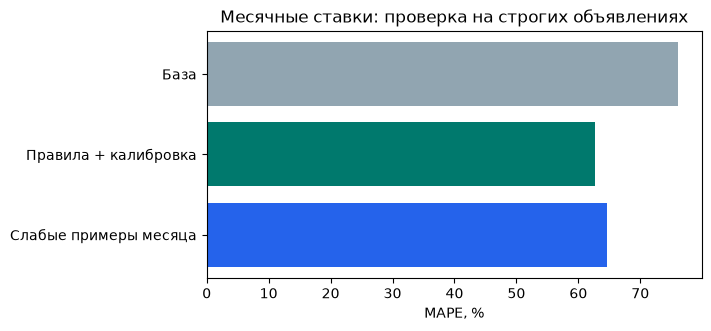

,variant,n,accuracy,balanced_accuracy,macro_f1
0,majority,4147,0.7287,0.1429,0.1204
1,text_classifier,4147,0.6870,0.2595,0.2476


,unit,variant,n,mape,coverage
0,month,unit_card,107,0.6233,0.2056
4,month,unit_card_calibrated,107,0.6959,0.4860
8,month,unit_ridge_tfidf,107,0.5969,0.4673
12,shift,unit_card,111,0.4381,0.2162
16,shift,unit_card_calibrated,111,0.4826,0.6216
20,shift,unit_ridge_tfidf,111,0.4890,0.3604


In [5]:
m = pd.read_csv(RESULTS / "metrics.csv")
def present(q, cols):
    v=q[cols].copy()
    if "variant" in v: v["variant"]=v.variant.map(variants)
    return v.round(4).reset_index(drop=True)

for cohort in ("strict","broad"):
    print(cohort)
    q=m.loc[m.cohort.eq(cohort)&m.dimension.eq("all")]
    display(present(q,["variant","n","mape","median_ape","coverage","pinball_log"]))
print("Строгий срез по периоду")
q=m.loc[m.cohort.eq("strict")&m.dimension.eq("unit")&
        m.variant.isin(["empirical","rules_calibrated","augmented_month"])]
display(present(q,["variant","key","n","groups","mape","median_ape","coverage"]))
monthly=q.loc[q.key.eq("month")].set_index("variant").reindex(["empirical","rules_calibrated","augmented_month"])
fig,ax=plt.subplots(figsize=(7,3.2),layout="constrained")
ax.barh(["База","Правила + калибровка","Слабые примеры месяца"],100*monthly.mape,
        color=["#91a5b1","#00796d","#2563eb"])
ax.set(xlabel="MAPE, %", title="Месячные ставки: проверка на строгих объявлениях")
ax.invert_yaxis()
plt.show()
display(pd.read_csv(RESULTS / "format_metrics.csv").round(4))
specialists = pd.read_csv(RESULTS / "specialists_strict_metrics.csv")
display(specialists.loc[specialists.quote_kind.eq("all"), ["unit","variant","n","mape","coverage"]].round(4))

## 4. Прогноз из сохранённых результатов

Пример на вымышленной карточке без числа зарплаты. Контекст задан явно. Поле references показывает, сколько строгих ставок соответствовало этому контексту. Даже при наличии прогноза маленькая выборка ограничивает доверие к интервалу.

Качество на строгом наборе пока недостаточно для автоматического продукта. Для проверки цен используйте подтверждённую единицу и сопоставимые объявления по соответствующей роли.

In [6]:
offer = pd.DataFrame([{"title":"Удалённый оператор поддержки",
    "description":"Входящие обращения, без продаж. Работа по московскому времени. Нужны компьютер и гарнитура.",
    "Формат работы":"Удалённо", "Занятость":"Полная", "Количество рабочих часов в день":"8"}])
request = {"unit":"month","tax":"net","quote_kind":"central"}
for variant in ("rules_calibrated","unit_ridge","empirical"):
    print(variants[variant])
    result=infer(offer,**request,folder=RESULTS,variant=variant)
    assert result.p25.le(result.p50).all() and result.p50.le(result.p75).all()
    display(result.round({"p25":0,"p50":0,"p75":0}))

CatBoost с правилами и калибровкой


,id,unit,tax,quote_kind,role,references,low_support,p25,p50,p75
0,1,month,net,central,Операторы,62,False,23706.0,45938.0,69353.0


Отдельный Ridge + TF-IDF


,id,unit,tax,quote_kind,role,references,low_support,p25,p50,p75
0,1,month,net,central,Операторы,62,False,32967.0,51077.0,71094.0


База по профессии и типу ставки


,id,unit,tax,quote_kind,role,references,low_support,p25,p50,p75
0,1,month,net,central,Операторы,62,False,37500.0,48750.0,63125.0


## 5. Как переобучить

Поставьте RUN_TRAINING = True для полного повторного запуска. Сначала проверяется хеш снимка; результаты пишутся в отдельную папку внутри проекта. По умолчанию используются сохранённые веса и прогнозы.

In [7]:
RUN_TRAINING = False
if RUN_TRAINING:
    run = ROOT / "ML/.cache/remote_runs" / f"{datetime.now():%Y%m%d-%H%M%S-%f}"
    run.mkdir(parents=True)
    source = ROOT / "Data/dataset/vacancies.csv"
    if not source.is_file():
        from utils.build_dataset import assemble
        manifest=json.loads((ROOT/"Data/dataset/manifest.json").read_text(encoding="utf8"))
        source=run/"vacancies.csv"
        source.write_bytes(assemble(manifest,lambda name:subprocess.check_output(
            ["git","show",f"HEAD:Data/dataset/{name}"],cwd=ROOT)))
    with source.open("rb") as f:
        assert hashlib.file_digest(f,"sha256").hexdigest()==meta["snapshot_sha256"]
    env=os.environ.copy()
    if LOCAL_DEPS.is_dir():
        env["PYTHONPATH"]=os.pathsep.join(filter(None,[str(LOCAL_DEPS),env.get("PYTHONPATH")]))
    for script,extra in [("remote_data.py",["--data",str(source)]),("remote_train.py",[]),("remote_specialists.py",[])]:
        subprocess.run([sys.executable,"-X","utf8",str(EXP/script),"--cache",str(run/"cache"),
                        "--out",str(run/"results"),*extra],cwd=ROOT,env=env,check=True)
    subprocess.run([sys.executable,"-X","utf8",str(EXP/"remote_audit.py"),"--out",str(run/"results")],
                   cwd=ROOT,env=env,check=True)
    print(run/"results")
else:
    print("Использованы сохранённые метрики и веса.")

Использованы сохранённые метрики и веса.
